# Step 5: Neural Rankers and the Dual-Horizon Attention Ranker (DHAR)

**BT4222 Final Project, Group 13, JDSearch**

Step 5 asks whether a neural model that reads the user's history sequence can beat LambdaMART on the same features. It trains the proposed **DHAR** (two attention towers, one over recent intent and one over past orders) together with four feature-based controls and a separate history-conditioned CF baseline. The feature-based controls compare history representations under the same training protocol; CF also changes the inputs and architecture.

## How to read this notebook

The model and training functions match `src/step5_neural.py` verbatim; notebook setup and result checks are additional cells. `tests/test_notebooks.py` checks the shared code. Each cell is preceded by a short explanation of what it does and
why, and the table below links every section to the function that implements it and to the file it
produces, so any number in the report can be traced back to a cell.

* **Part A** rebuilds the step. It needs the inputs listed below.
* **Part B** reads the measured outputs of the corrected run (`artifacts/corrected`) and re-checks them.
  It needs no raw data, so it always runs and its outputs are saved in this copy of the notebook.

| Section | What it does | Code in `src/step5_neural.py` | Writes |
|---|---|---|---|
| A.1 | Variants and constants | `VARIANTS`, `NAMES`, `BRAND_BUCKETS` | - |
| A.2 | Device and seeding | `device`, `seed_everything` | - |
| A.3 | Preprocessing fitted on training data | `brand_bucket`, `fit_preprocessing` | `neural_preprocessing.json` |
| A.4 | Encode frames, build history sequences | `encode_frames` | - |
| A.5 | Pack slates into tensors | `pack` | - |
| A.6 | The models | `DHAR`, `HistoryCF` | - |
| A.7 | Listwise loss, batching, prediction | `listwise`, `forward_batch`, `predict_pack` | - |
| A.8 | Training loop with early stopping | `train_one` | `<variant>_seed<k>.pt`, `training_<variant>_seed<k>.json` |
| A.9 | Run every variant | `main()` | `results_neural.json`, `test_pred_neural.parquet`, `horizon_coverage.json` |
| B.1 | Neural results | - | - |
| B.2 | Recompute from saved predictions | - | - |
| B.3 | Training curves and sequence coverage | - | - |

**Inputs.** `features.parquet`, `history.parquet`, `meta_subset.parquet` (Steps 2 and 3).

**Outputs.** One checkpoint and training log per variant, `results_neural.json`, `test_pred_neural.parquet` (test scores of all variants).

**Saved-output provenance.** This copy executes Part B against the committed corrected-run predictions and training logs. Part A defines the training code but its training calls are skipped (`RUN_STEP = False`); the saved outputs do not represent a fresh neural training run. The reported neural scores already use the corrected features, unlike the earlier Step 7 draft.

## The six variants

All variants are trained with the same data, packing, loss, optimiser, early stopping and seed. The five feature-based variants share the DHAR class and head; history-conditioned CF has a separate item-based architecture and does not use the engineered features.

| Key | Name | What it sees |
|---|---|---|
| `mlp` | MLP (no towers) | candidate category + brand embeddings and the 26 features; **no history sequence** |
| `pooled` | Pooled history | as `mlp` plus the **mean** of the user's recent-intent and order category embeddings (history without attention) |
| `short_only` | Short only | as `mlp` plus an attention tower over the recent-intent sequence |
| `order_only` | Order only | as `mlp` plus an attention tower over the order sequence |
| `dual` | **DHAR** | as `mlp` plus **both** towers: the candidate's category embedding attends separately over recent intent and over past orders |
| `history_cf` | History-conditioned CF | an NCF-style model of item embeddings with the user represented by the mean of up to 40 known item embeddings sampled evenly across their complete preceding history (no engineered features) |

The key comparison is `dual` against `mlp`: both receive the same engineered history features, so the
comparison tests the incremental benefit of the history towers in this run. It does not establish equivalence or prove that history sequences contain no additional information.

**Training details.** Listwise loss: a softmax over each slate trained against the normalised gains
`[0, 1, 3, 7]` (slates without a positive are skipped). Training slates are cut to 64 candidates (all
positives plus a seeded sample of negatives); validation and test use the **full** slates (up to 200).
Adam, learning rate 0.002, batch 128, at most 20 epochs, stop after 3 epochs without validation gain and
keep the best checkpoint. Embedding size 32. The feature-based head is 128-64-1 with dropout 0.2; CF combines a GMF product with a separate 64-32 MLP branch. Sequences keep up to 20
category ids, evenly spaced over the whole horizon (40 items for `history_cf`); unknown or training-unseen category ids are dropped before category sampling; CF drops items outside its training vocabulary.

## 0. Environment setup

The first cell finds the project and puts `src/` on `sys.path`, so `config`, `data_utils`
and `eval_utils` can be imported exactly as the scripts do.

* **In Colab** it clones the repository (branch set in `BRANCH`). Set `MOUNT_DRIVE = True` if the
  raw files live on Google Drive: raw paths and the output folder then point to Drive, so the
  outputs of one step survive until the next notebook.
* **Locally** it looks for `Final Project/` next to the notebook.
* All paths come from environment variables read by `src/config.py`:
  `JD_USER_TXT`, `JD_PRODUCT_TXT` (raw files), `JD_RUN_DIR` (where outputs are written, default
  `artifacts/corrected`), `JD_SEED` (default 42).

In [1]:
# Optional: install dependencies in a fresh environment (Colab already has most of them)
# !pip -q install numpy pandas pyarrow scipy scikit-learn lightgbm joblib matplotlib torch

import os, sys, subprocess
from pathlib import Path

REPO_URL = "https://github.com/steffanylars/nus-web-mining-business-insights.git"
BRANCH = "main"   # final submission branch
MOUNT_DRIVE = False                    # Colab only: True keeps raw data and outputs on Google Drive
DRIVE_DIR = "/content/drive/MyDrive/JDsearch"

IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    if MOUNT_DRIVE:
        from google.colab import drive
        drive.mount("/content/drive")
        os.environ.setdefault("JD_USER_TXT", f"{DRIVE_DIR}/user_behavior_data.txt")
        os.environ.setdefault("JD_PRODUCT_TXT", f"{DRIVE_DIR}/product_meta_data.txt")
        os.environ.setdefault("JD_RUN_DIR", f"{DRIVE_DIR}/runs/corrected")
    repo = Path("/content/nus-web-mining-business-insights")
    if not (repo / ".git").exists():
        subprocess.run(["git", "clone", "--branch", BRANCH, REPO_URL, str(repo)], check=True)
    PROJECT_ROOT = repo / "Final Project"
else:
    here = Path.cwd()
    options = [here, here.parent, here / "Final Project", here.parent / "Final Project"]
    PROJECT_ROOT = next((p for p in options if (p / "src" / "config.py").exists()), None)
    assert PROJECT_ROOT is not None, "open this notebook from Final Project/ or Final Project/notebooks/"

SRC = PROJECT_ROOT / "src"
if str(SRC) not in sys.path:
    sys.path.insert(0, str(SRC))
print("in Colab    :", IN_COLAB)
print("project root:", PROJECT_ROOT)
print("run dir     :", os.environ.get("JD_RUN_DIR", "<default: artifacts/corrected>"))

in Colab    : False
project root: /Users/steff/Documents/GitHub/bt4212_finalProj/Final Project
run dir     : /Users/steff/Documents/GitHub/bt4212_finalProj/local_run/outputs


## 1. Imports and shared helpers

PyTorch builds the models. `short_mask` and `select_sequence` (in `data_utils`) define the short
horizon and the even sampling of a long history; `evaluate` is the shared scorer.

In [2]:
import copy, hashlib, json, math, random, time
import numpy as np
import pandas as pd
import torch
from torch import nn
from torch.nn import functional as F
import matplotlib.pyplot as plt
from IPython.display import display

from config import (OUT, RES, SEED, HISTORY_LENGTH, EPOCHS, BATCH_SIZE, THREADS,
                    feature_columns, prepare, save_json)
from data_utils import short_mask, select_sequence
from eval_utils import evaluate

%matplotlib inline
prepare()
print("history length:", HISTORY_LENGTH, "| max epochs:", EPOCHS, "| batch size:", BATCH_SIZE)

history length: 20 | max epochs: 20 | batch size: 128


### 1.1 What can run here? (the `RUN_STEP` switch)

Part A rebuilds this step and Part B reads the measured outputs, so the switch below decides whether
Part A runs.

* Part A runs only if its **inputs exist**, and it will not overwrite the committed evidence in
  `artifacts/corrected` unless you explicitly allow it (`ALLOW_OVERWRITE`). In Colab the clone is
  disposable, so overwriting is allowed by default; locally, point `JD_RUN_DIR` at a new folder.
* If Part A is skipped, nothing fails: Part B reads results from the selected run if present, otherwise from the committed corrected run. It prints the source folder explicitly.

In [3]:
COMMITTED = (PROJECT_ROOT / "artifacts" / "corrected").resolve()
ALLOW_OVERWRITE = IN_COLAB      # a Colab clone is disposable; locally keep the committed evidence safe
HAS_INPUTS = all((OUT / f"{n}.parquet").exists() for n in ["features", "history", "meta_subset"])
RUN_STEP = HAS_INPUTS and (RES.resolve() != COMMITTED or ALLOW_OVERWRITE)

print("inputs found    :", HAS_INPUTS)
print("outputs go to   :", RES)
print("RUN_STEP        :", RUN_STEP)
if not RUN_STEP:
    why = ("required inputs not found: features, history, meta_subset parquet files (run Steps 2 and 3 first)" if not HAS_INPUTS else
           "outputs would overwrite artifacts/corrected; set JD_RUN_DIR to a new folder or ALLOW_OVERWRITE = True")
    print("Part A is skipped here (" + why + ").")
    print("Part B below selects and prints its saved-result source.")

inputs found    : True
outputs go to   : /Users/steff/Documents/GitHub/bt4212_finalProj/local_run/outputs
RUN_STEP        : True


# Part A: Train the neural rankers

### A.1 Variants and constants

In [4]:
VARIANTS = ['mlp','pooled','short_only','order_only','dual','history_cf']
NAMES = {'mlp':'MLP(no towers)','pooled':'Pooled history','short_only':'Short only',
         'order_only':'Order only','dual':'DHAR(ours)','history_cf':'History-conditioned CF'}
BRAND_BUCKETS = 20000

### A.2 Device and seeding

The device is picked automatically (CUDA, then Apple MPS, then CPU). `seed_everything` fixes Python,
NumPy and PyTorch for repeatable sampling and initialization. A fixed seed does not guarantee identical results across devices or library versions.

In [5]:
def device():
    return torch.device('cuda' if torch.cuda.is_available() else
                        'mps' if torch.backends.mps.is_available() else 'cpu')

def seed_everything(seed):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

### A.3 Preprocessing fitted on training data only

`fit_preprocessing` computes everything the models need to turn raw columns into inputs: mean and
standard deviation of each feature (training rows only), the vocabulary of level-3 categories and of
items seen in training, and the hashing of brand ids into 20,000 buckets (`brand_bucket`, a stable hash,
so the same brand always gets the same bucket in any run). Validation and test never influence it.

In [6]:
def brand_bucket(value):
    if value is None or pd.isna(value) or str(value).strip() in {'','-1'}:
        return 0
    digest=hashlib.blake2b(str(value).encode(),digest_size=8).digest()
    return int.from_bytes(digest,'little')%(BRAND_BUCKETS-1)+1

def fit_preprocessing(feat,hist,meta,length):
    cols=feature_columns(feat); train=feat.split.eq('train')
    train_ids=set(feat.loc[train,'session_id'])
    train_hist=hist[hist.session_id.isin(train_ids)]
    train_wids=set(feat.loc[train,'cand_wid'])|set(train_hist.wid)
    tm=meta[meta.wid.isin(train_wids)]
    categories=sorted(c for c in tm.cate_id_3.dropna().unique() if str(c).strip())
    mu=feat.loc[train,cols].mean()
    sd=feat.loc[train,cols].std().fillna(1).replace(0,1)
    return dict(schema_version=2,feature_columns=cols,mean=mu.tolist(),std=sd.tolist(),
        category_ids={str(c):i+1 for i,c in enumerate(categories)},
        item_ids={w:i+1 for i,w in enumerate(sorted(train_wids))},
        history_length=length,cf_history_length=2*length,brand_buckets=BRAND_BUCKETS,
        brand_hash='blake2b UTF-8, 8 bytes little-endian; modulo 19999 + 1',
        sequence_policy='evenly spaced positions over each complete chronological horizon',
        short_policy='CLICK <=7d or CART <=90d',order_policy='all preceding ORD events')

### A.4 Encode features and build the history sequences

`encode_frames` standardises the features, maps each candidate to category, brand and item ids, and
builds three sequences per session from the **complete** history: the **short** sequence (clicks of the
last 7 days and carts of the last 90 days), the **order** sequence (all orders) and the **cf** sequence
(every event, for the collaborative-filtering variant). Unknown ids are removed first, then up to
`length` positions are sampled evenly across the horizon. The returned `coverage` table reports how
many events were eligible, unknown and kept.

In [7]:
def encode_frames(feat,hist,meta,prep):
    frame=feat.copy()
    cols=prep['feature_columns']
    frame[cols]=((frame[cols]-np.array(prep['mean']))/np.array(prep['std'])).astype('float32')
    if not np.isfinite(frame[cols].to_numpy()).all():
        raise ValueError('Nonfinite neural features')
    maps=meta.set_index('wid')
    cat=maps.cate_id_3.to_dict(); brand=maps.brand_id.to_dict()
    frame['_c3']=frame.cand_wid.map(cat).map(prep['category_ids']).fillna(0).astype(int)
    frame['_bi']=frame.cand_wid.map(brand).map(brand_bucket).astype(int)
    frame['_ii']=frame.cand_wid.map(prep['item_ids']).fillna(0).astype(int)
    h=hist.sort_values(['session_id','pos']).copy()
    h['_c3']=h.wid.map(cat).map(prep['category_ids']).fillna(0).astype(int)
    h['_ii']=h.wid.map(prep['item_ids']).fillna(0).astype(int)
    sequences={}; coverage={}
    for name,subset,col,length in [
        ('short',h[short_mask(h)],'_c3',prep['history_length']),
        ('order',h[h.type.eq('ORD')],'_c3',prep['history_length']),
        ('cf',h,'_ii',prep['cf_history_length'])]:
        seq={}; eligible=retained=unknown=0
        for sid,g in subset.groupby('session_id',sort=False):
            values=g[col].to_numpy()
            eligible+=len(values); unknown+=int((values==0).sum())
            # Unknown metadata/items are excluded before position sampling.
            selected=select_sequence(values[values>0],length)
            seq[sid]=selected; retained+=len(selected)
        sequences[name]=seq
        coverage[name]={'eligible_events':eligible,'unknown_events':unknown,'selected_events':retained,
                        'users_with_known_sequence':sum(bool(len(v)) for v in seq.values())}
    return frame,sequences,coverage

### A.5 Pack the slates into tensors

`pack` stacks each split into fixed-width arrays (features, ids, labels, mask, sequences). Candidates are
put in a canonical order so file order cannot influence sampling or rounding. Training slates wider than
the width are reduced to all positives plus a seeded sample of negatives; evaluation slates must fit
entirely or the function raises an error, so no candidate is ever silently dropped from evaluation.

In [8]:
def pack(frame,sequences,prep,split,width=200,seed=SEED):
    cols=prep['feature_columns']; groups=frame[frame.split.eq(split)].groupby('session_id',sort=True)
    n=len(groups); nf=len(cols); L=prep['history_length']; H=prep['cf_history_length']
    arrays=dict(num=np.zeros((n,width,nf),dtype=np.float32),
        c3=np.zeros((n,width),dtype=np.int64),bi=np.zeros((n,width),dtype=np.int64),
        ii=np.zeros((n,width),dtype=np.int64),lab=np.zeros((n,width),dtype=np.int64),
        mask=np.zeros((n,width),dtype=bool),ridx=np.full((n,width),-1,dtype=np.int64),
        short=np.zeros((n,L),dtype=np.int64),order=np.zeros((n,L),dtype=np.int64),
        cf=np.zeros((n,H),dtype=np.int64))
    for row,(sid,g) in enumerate(groups):
        # Canonical order prevents source positions influencing sampling/roundoff.
        g=g.sort_values('cand_wid')
        if len(g)>width:
            if split!='train':
                raise ValueError('Evaluation must use every supplied candidate')
            rng=np.random.default_rng(np.random.SeedSequence([seed,int(sid)]))
            pos=np.flatnonzero(g.label.to_numpy()>0); neg=np.flatnonzero(g.label.to_numpy()==0)
            if len(pos)>width:
                raise ValueError('Training width is smaller than number of positives')
            selected=np.r_[pos,rng.choice(neg,width-len(pos),replace=False)]
            g=g.iloc[selected].sort_values('cand_wid')
        m=len(g)
        arrays['num'][row,:m]=g[cols].to_numpy(dtype=np.float32)
        for key,col in [('c3','_c3'),('bi','_bi'),('ii','_ii'),('lab','label')]:
            arrays[key][row,:m]=g[col].to_numpy()
        arrays['mask'][row,:m]=True; arrays['ridx'][row,:m]=g.index.to_numpy()
        for key in ['short','order','cf']:
            v=sequences[key].get(sid,[])
            arrays[key][row,:len(v)]=v
    return {k:torch.from_numpy(v) for k,v in arrays.items()}

### A.6 The models

`DHAR.forward` builds the candidate representation from its category and brand embeddings, then
switches on the towers according to `variant`:

* `attend` scores the candidate's category embedding against every category in a history sequence
  (scaled dot product after a learned projection), masks the padding, and returns the attention-weighted
  sum;
* `dual` uses a short tower (`ps`) and an order tower (`pl`); `short_only` / `order_only` use one;
  `pooled` replaces attention by a plain mean; `mlp` uses neither;
* the head receives `[category embedding, brand embedding, short context, order context, 26 features]`.

`HistoryCF` is the neural collaborative-filtering control: the user is the mean embedding of their
history items, the candidate an item embedding, combined by a product (GMF) branch and an MLP branch.

In [9]:
class DHAR(nn.Module):
    def __init__(self,nc3,nb,nf,variant='dual',d=32,**unused):
        super().__init__(); self.variant=variant
        self.ec3=nn.Embedding(nc3,d,padding_idx=0); self.eb=nn.Embedding(nb,d,padding_idx=0)
        self.ps=nn.Linear(d,d); self.pl=nn.Linear(d,d)
        self.head=nn.Sequential(nn.Linear(4*d+nf,128),nn.ReLU(),nn.Dropout(.2),
            nn.Linear(128,64),nn.ReLU(),nn.Dropout(.2),nn.Linear(64,1))
    def attend(self,q,seq,projection):
        emb=self.ec3(seq); mask=seq>0
        score=torch.einsum('bsd,bld->bsl',projection(q),emb)/math.sqrt(emb.size(-1))
        score=score.masked_fill(~mask[:,None,:],-1e9)
        weight=torch.softmax(score,dim=-1)*mask[:,None,:]
        weight=weight/weight.sum(-1,keepdim=True).clamp_min(1e-9)
        return torch.einsum('bsl,bld->bsd',weight,emb)
    def forward(self,num,c3,bi,ii,short,order,cf):
        qc=self.ec3(c3); qb=self.eb(bi); sc=torch.zeros_like(qc); lc=torch.zeros_like(qc)
        if self.variant in {'dual','short_only'}:
            sc=self.attend(qc,short,self.ps)
        if self.variant in {'dual','order_only'}:
            lc=self.attend(qc,order,self.pl)
        if self.variant=='pooled':
            both=torch.cat([short,order],dim=1); mask=both>0
            pool=(self.ec3(both)*mask[:,:,None]).sum(1)/mask.sum(1,keepdim=True).clamp_min(1)
            sc=pool[:,None,:].expand_as(qc); lc=sc
        return self.head(torch.cat([qc,qb,sc,lc,num],dim=-1)).squeeze(-1)

class HistoryCF(nn.Module):
    """GMF+MLP with a mean history encoder instead of per-session embeddings."""
    def __init__(self,ni,d=32,**unused):
        super().__init__()
        self.item=nn.Embedding(ni,d,padding_idx=0)
        self.mlp=nn.Sequential(nn.Linear(2*d,64),nn.ReLU(),nn.Linear(64,32),nn.ReLU())
        self.out=nn.Linear(d+32,1)
    def forward(self,num,c3,bi,ii,short,order,cf):
        mask=cf>0
        user=(self.item(cf)*mask[:,:,None]).sum(1)/mask.sum(1,keepdim=True).clamp_min(1)
        candidate=self.item(ii); user=user[:,None,:].expand_as(candidate)
        return self.out(torch.cat([user*candidate,self.mlp(torch.cat([user,candidate],-1))],-1)).squeeze(-1)

### A.7 Loss, batching and prediction

* `listwise` turns each slate's gains into a target distribution and minimises the cross-entropy to the
  softmax of the scores, so the model learns the **order** within a slate, with purchases weighing more.
* `forward_batch` moves one batch to the device and calls the model.
* `predict_pack` scores a whole split and writes each score back to the row it came from (`ridx`), which
  keeps predictions aligned with the original frame.

In [10]:
def listwise(scores,lab,mask):
    gain=torch.tensor([0.,1.,3.,7.],device=scores.device)[lab]*mask
    target=gain/gain.sum(1,keepdim=True).clamp_min(1e-9)
    loss=-(target*F.log_softmax(scores.masked_fill(~mask,-1e9),dim=1)).sum(1)
    positive=gain.sum(1)>0
    return loss[positive].mean() if positive.any() else scores.sum()*0

def forward_batch(model,pk,indices,dev):
    return model(*[pk[k][indices].to(dev) for k in ['num','c3','bi','ii','short','order','cf']])

def predict_pack(model,pk,n_rows,dev):
    model.eval(); scores=np.zeros(n_rows,dtype=np.float32)
    with torch.no_grad():
        for a in range(0,len(pk['num']),BATCH_SIZE):
            sl=slice(a,a+BATCH_SIZE)
            value=forward_batch(model,pk,sl,dev).cpu().numpy()
            ids=pk['ridx'][sl].numpy(); mask=pk['mask'][sl].numpy()
            scores[ids[mask]]=value[mask]
    return scores

### A.8 Training one variant

For each epoch: shuffle the training slates, minimise the listwise loss, score the validation slates and
compute NDCG@10. The best validation checkpoint is kept (patience 3), saved as `<variant>_seed<k>.pt`,
and the loss and validation curve are logged in `training_<variant>_seed<k>.json`.

In [11]:
def train_one(variant,prep,frame,packs,seed,dev):
    seed_everything(seed)
    spec=dict(nc3=len(prep['category_ids'])+1,nb=prep['brand_buckets'],
              nf=len(prep['feature_columns']),ni=len(prep['item_ids'])+1,variant=variant)
    model=(HistoryCF(**spec) if variant=='history_cf' else DHAR(**spec)).to(dev)
    optimizer=torch.optim.Adam(model.parameters(),lr=.002,weight_decay=1e-6)
    best=-1.; state=None; bad=0; log=[]; start=time.time()
    val=frame[frame.split.eq('val')].copy()
    tr=packs['train']
    for epoch in range(1,EPOCHS+1):
        model.train(); perm=np.random.permutation(len(tr['num'])); total=0.; batches=0
        for a in range(0,len(perm),BATCH_SIZE):
            ix=perm[a:a+BATCH_SIZE]
            score=forward_batch(model,tr,ix,dev)
            loss=listwise(score,tr['lab'][ix].to(dev),tr['mask'][ix].to(dev))
            optimizer.zero_grad(); loss.backward(); optimizer.step()
            total+=float(loss.detach()); batches+=1
        scores=predict_pack(model,packs['val'],len(frame),dev)
        val['score']=scores[val.index.to_numpy()]
        metrics,n=evaluate(val,'score'); ndcg=metrics['NDCG@10']
        log.append(dict(epoch=epoch,loss=total/max(batches,1),val_ndcg10=ndcg))
        print(f'{variant} seed={seed} epoch={epoch} val={ndcg:.5f} elapsed={time.time()-start:.0f}s',flush=True)
        if ndcg>best:
            best=ndcg; state=copy.deepcopy({k:v.detach().cpu() for k,v in model.state_dict().items()}); bad=0
        else:
            bad+=1
            if bad>=3: break
    model.load_state_dict(state)
    name=f'{variant}_seed{seed}'
    torch.save({'state_dict':state,'spec':spec,'schema_version':2},OUT/f'{name}.pt')
    save_json(RES/f'training_{name}.json',dict(seed=seed,variant=variant,epochs=log,
        best_validation_ndcg10=best,training_slate_width=packs['train']['mask'].shape[1],
        evaluation_slate_width=200,batch_size=BATCH_SIZE,device=str(dev)))
    return model

### A.9 Run every variant

`RUN_VARIANTS` can be shortened for a quick trial (for example `["mlp", "dual"]`). The cells
below are the body of `main()`: fit the preprocessing, encode and pack once (so **every variant sees the
same negatives and the same evaluation slates**), then train and evaluate each variant on test and
validation, saving results after every variant so completed results can be inspected if a run stops. This loop does not automatically resume training from an interrupted checkpoint.

In [12]:
RUN_VARIANTS = VARIANTS      # e.g. ["mlp", "dual"] for a quick trial
RUN_SEEDS = [SEED]

In [13]:
if RUN_STEP:
    prepare(); torch.set_num_threads(THREADS); dev=device()
    print('device',dev,flush=True)

device mps


In [14]:
if RUN_STEP:
    feat=pd.read_parquet(OUT/'features.parquet')
    hist=pd.read_parquet(OUT/'history.parquet')
    meta=pd.read_parquet(OUT/'meta_subset.parquet')
    prep=fit_preprocessing(feat,hist,meta,HISTORY_LENGTH)
    save_json(OUT/'neural_preprocessing.json',prep)

In [15]:
if RUN_STEP:
    frame,sequences,coverage=encode_frames(feat,hist,meta,prep)
    save_json(RES/'horizon_coverage.json',coverage)
    # Same fixed negative sample and complete eval slates for every architecture.
    packs={s:pack(frame,sequences,prep,s,64 if s=='train' else 200)
           for s in ['train','val','test']}

In [16]:
if RUN_STEP:
    results={}; predictions=feat.loc[feat.split.eq('test'),['session_id','cand_wid','label']].copy()
    for seed in RUN_SEEDS:
        for variant in RUN_VARIANTS:
            model=train_one(variant,prep,frame,packs,seed,dev)
            key=NAMES[variant] if len(RUN_SEEDS)==1 else f'{NAMES[variant]} seed{seed}'
            test_scores=predict_pack(model,packs['test'],len(frame),dev)
            col=f'{variant}_score' if len(RUN_SEEDS)==1 else f'{variant}_seed{seed}_score'
            predictions[col]=test_scores[predictions.index.to_numpy()]
            m,n=evaluate(predictions,col); results[key]=m
            print('TEST',key,m,flush=True)
            val=frame[frame.split.eq('val')].copy()
            score=predict_pack(model,packs['val'],len(frame),dev)
            val['score']=score[val.index.to_numpy()]
            results[key+'_val']=evaluate(val,'score')[0]
            # Incremental saves allow a long CPU run to be resumed/reviewed.
            predictions.to_parquet(OUT/'test_pred_neural.parquet',index=False)
            save_json(RES/'results_neural.json',results)
            del model
    print('Neural variants complete',flush=True)

mlp seed=42 epoch=1 val=0.36677 elapsed=1s


mlp seed=42 epoch=2 val=0.36807 elapsed=2s


mlp seed=42 epoch=3 val=0.36730 elapsed=3s


mlp seed=42 epoch=4 val=0.36641 elapsed=3s


mlp seed=42 epoch=5 val=0.35799 elapsed=4s


TEST MLP(no towers) {'NDCG@10': 0.37299591176991004, 'MRR@200': 0.3835793623215414, 'P@1': 0.251602023608769, 'HR@10': 0.6617200674536257}


... (35 outputs left out)

history_cf seed=42 epoch=13 val=0.27203 elapsed=34s


history_cf seed=42 epoch=14 val=0.27253 elapsed=37s


TEST History-conditioned CF {'NDCG@10': 0.26727564802668036, 'MRR@200': 0.2682860080980373, 'P@1': 0.13794266441821249, 'HR@10': 0.5480607082630692}


Neural variants complete


# Part B: Verify saved neural results

The source directory below is the selected run when it contains neural results, otherwise the committed corrected run. All checks read predictions and summaries from that same directory. The default corrected run has 3,000 test queries, of which 2,965 contain a positive; all-negative queries are excluded from the ranking averages.

### B.1 Neural results

Validation NDCG@10 selects checkpoints; the other columns are held-out test metrics. The baseline score is read from the same run when available.

In [17]:
SAVED = RES if (RES / "results_neural.json").exists() else COMMITTED
print("Saved-result source:", SAVED)
res = json.loads((SAVED / "results_neural.json").read_text(encoding="utf-8"))
test_rows = {k: v for k, v in res.items() if not k.endswith("_val")}
val_rows = {k[:-4]: v for k, v in res.items() if k.endswith("_val")}
table = pd.DataFrame(test_rows).T[["NDCG@10", "MRR@200", "P@1", "HR@10"]]
table.insert(0, "val NDCG@10", pd.Series({k: v["NDCG@10"] for k, v in val_rows.items()}))
display(table.round(4))
baseline_path = SAVED / "results_baselines_lgb.json"
if baseline_path.exists():
    baseline = json.loads(baseline_path.read_text(encoding="utf-8"))
    print("Same-run LambdaMART test NDCG@10:", baseline["LambdaMART(features)"]["NDCG@10"])


Saved-result source: /Users/steff/Documents/GitHub/bt4212_finalProj/local_run/outputs


,val NDCG@10,NDCG@10,MRR@200,P@1,HR@10
MLP(no towers),0.3681,0.3730,0.3836,0.2516,0.6617
Pooled history,0.3665,0.3735,0.3831,0.2486,0.6658
Short only,0.3678,0.3735,0.3835,0.2489,0.6644
Order only,0.3676,0.3710,0.3813,0.2465,0.6587
DHAR(ours),0.3683,0.3747,0.3846,0.2499,0.6648
History-conditioned CF,0.2726,0.2673,0.2683,0.1379,0.5481


Same-run LambdaMART test NDCG@10: 0.3630055454799993


**Reading the committed corrected run.** The five feature-based variants score 0.371 to 0.374 NDCG@10, above LambdaMART's 0.3630. DHAR scores 0.3713 and the same-feature MLP scores 0.3725. Step 6 reports DHAR minus MLP as -0.0012, with a paired-query bootstrap 95% interval of [-0.0034, +0.0011]. This run does not establish an advantage for the attention towers; the interval does not prove the models are equivalent. DHAR minus LambdaMART is +0.0083, with interval [+0.0022, +0.0145]. These intervals condition on the fitted models and do not measure training-seed uncertainty.

History-conditioned CF scores 0.2694, below popularity (0.3045). Because CF also uses different inputs and a different architecture, this gap cannot be attributed solely to removing engineered features. These numbers describe the committed corrected run; a custom rerun may differ.

### B.2 Recompute every reported test metric

Check every saved model's NDCG@10, MRR@200, P@1 and HR@10 against its predictions. Verify the full query/candidate population and labels against Step 4 when same-run baseline predictions are available. Multiple seeds and subsets of variants are supported.

In [18]:
npred = pd.read_parquet(SAVED / "model" / "test_pred_neural.parquet")
keys = ["session_id", "cand_wid"]
assert not npred.duplicated(keys).any(), "duplicate query/candidate keys"
rows = []
checked_models = set()
positive_queries = None
for col in [c for c in npred if c.endswith("_score")]:
    variant = col.removesuffix("_score")
    if "_seed" in variant:
        variant, seed = variant.rsplit("_seed", 1)
        name = f"{NAMES[variant]} seed{seed}"
    else:
        name = NAMES[variant]
    m, n = evaluate(npred, col)
    if positive_queries is None:
        positive_queries = n
    assert n == positive_queries, "model evaluation populations differ"
    checked_models.add(name)
    for metric, value in m.items():
        rows.append(dict(model=name, metric=metric, recomputed=value,
                         saved=res[name][metric], abs_diff=abs(value - res[name][metric])))
assert checked_models == set(test_rows), "saved metric models and prediction columns differ"
assert rows, "no prediction score columns found"
check = pd.DataFrame(rows).set_index(["model", "metric"])
display(check.round(9))
assert check.abs_diff.max() < 1e-9, "saved predictions do not reproduce all saved metrics"
print("max absolute difference:", check.abs_diff.max())
print("test candidates:", len(npred), "| all queries:", npred.session_id.nunique(),
      "| positive queries:", positive_queries)

baseline_pred_path = SAVED / "model" / "test_pred_lgb.parquet"
if baseline_pred_path.exists():
    baseline_pred = pd.read_parquet(baseline_pred_path, columns=keys + ["label"])
    paired = npred[keys + ["label"]].merge(
        baseline_pred, on=keys, how="outer", validate="one_to_one",
        suffixes=("_neural", "_baseline"), indicator=True)
    assert paired["_merge"].eq("both").all(), "Step 4 and Step 5 candidate populations differ"
    assert paired.label_neural.eq(paired.label_baseline).all(), "Step 4 and Step 5 labels differ"
    print("PASS: Step 4 and Step 5 use identical query/candidate keys and labels.")
else:
    print("No same-run Step 4 predictions; cross-step population check skipped.")


recomputed     saved  abs_diff
model                  metric                                 
MLP(no towers)         NDCG@10    0.372996  0.372996       0.0
                       MRR@200    0.383579  0.383579       0.0
                       P@1        0.251602  0.251602       0.0
                       HR@10      0.661720  0.661720       0.0
Pooled history         NDCG@10    0.373497  0.373497       0.0
                       MRR@200    0.383067  0.383067       0.0
                       P@1        0.248567  0.248567       0.0
                       HR@10      0.665767  0.665767       0.0
Short only             NDCG@10    0.373453  0.373453       0.0
                       MRR@200    0.383493  0.383493       0.0
                       P@1        0.248904  0.248904       0.0
                       HR@10      0.664418  0.664418       0.0
Order only             NDCG@10    0.370993  0.370993       0.0
                       MRR@200    0.381311  0.381311       0.0
                       P@1        0.246543  0.246543       0.0
                       HR@10      0.658685  0.658685       0.0
DHAR(ours)             NDCG@10    0.374705  0.374705       0.0
                       MRR@200    0.384623  0.384623       0.0
                       P@1        0.249916  0.249916       0.0
                       HR@10      0.664755  0.664755       0.0
History-conditioned CF NDCG@10    0.267276  0.267276       0.0
                       MRR@200    0.268286  0.268286       0.0
                       P@1        0.137943  0.137943       0.0
                       HR@10      0.548061  0.548061       0.0

max absolute difference: 0.0
test candidates: 266640 | all queries: 3000 | positive queries: 2965


PASS: Step 4 and Step 5 use identical query/candidate keys and labels.


### B.3 Training curves and sequence coverage

Validation NDCG@10 per epoch (early stopping keeps the best one). The coverage table shows how much of
the history reaches each sequence: unknown or training-unseen categories are dropped before sampling up to 20 positions per category horizon; CF uses up to 40 known items across the complete history. Counts are across all splits.

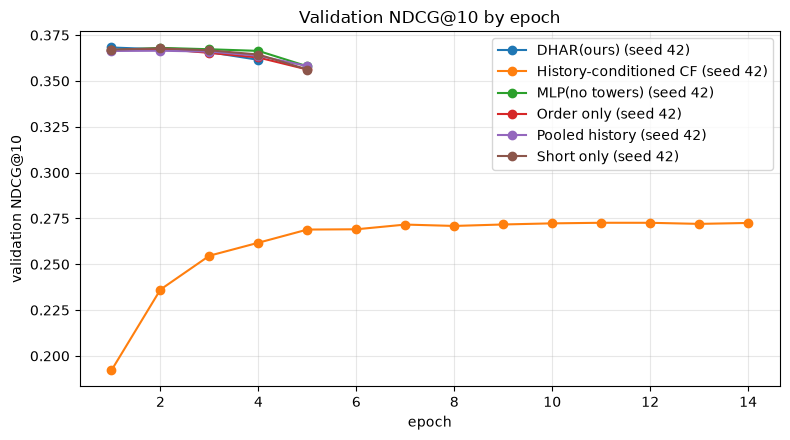

,eligible_events,unknown_events,selected_events,users_with_known_sequence,unknown_share
short,2301544,81178,337562,19569,0.035
order,785868,69835,237250,18200,0.089
cf,3091153,369011,631939,19893,0.119


In [19]:
fig, ax = plt.subplots(figsize=(8, 4.5))
for path in sorted(SAVED.glob("training_*_seed*.json")):
    log = json.loads(path.read_text(encoding="utf-8"))
    ax.plot([e["epoch"] for e in log["epochs"]], [e["val_ndcg10"] for e in log["epochs"]],
            marker="o", label=f'{NAMES[log["variant"]]} (seed {log["seed"]})')
ax.set(xlabel="epoch", ylabel="validation NDCG@10", title="Validation NDCG@10 by epoch")
ax.legend(); ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

coverage = pd.DataFrame(json.loads((SAVED / "horizon_coverage.json").read_text(encoding="utf-8"))).T
coverage["unknown_share"] = coverage.unknown_events / coverage.eligible_events
display(coverage.round(3))

# Summary of the committed corrected run

* The saved corrected experiment trained DHAR, four feature-based controls and a history-conditioned CF baseline. The five feature-based variants reach 0.371 to 0.374 test NDCG@10, above LambdaMART (0.3630).
* The same-feature MLP scores 0.3725 versus DHAR's 0.3713. The paired interval includes zero, so this experiment does not establish an incremental benefit from the attention towers. It does not prove equivalence or that sequences contain no useful information.
* B.2 independently recomputes all four reported metrics and checks the candidate population against Step 4. Part A training was not rerun for this saved notebook; training curves come from the committed training logs.
* One split and seed were used. Offline ranking scores and query-bootstrap intervals do not establish online business impact or robustness across training seeds.

**Hand-off to Step 6:** `test_pred_neural.parquet` (scores of every variant) and the checkpoints. Large checkpoints are regenerated locally and are not committed to Git.
